# 10 Thực nghiệm kiểm thử Minimax Agent (`depth = 2`, Ngân sách tìm kiếm & Đối đầu Baselines)

**Mục tiêu:** Đánh giá toàn diện tác tử tìm kiếm đối kháng cổ điển **`MinimaxAgent` (Cấp 3)** theo đúng đề bài cuối kỳ môn Trí tuệ Nhân tạo Nâng cao (§3.2, §3.5, §3.6):
1. **Kiểm thử chức năng bắt buộc (`MM-01` → `MM-06`):**
   - Đảm bảo tính hợp lệ, bất biến của `GameState`, tính tái lập với seed.
   - Tìm kiếm nước thắng tức thì (ăn Tư lệnh ở 1 hoặc 2 ply).
   - Né tránh bẫy chết Tư lệnh đối phương giăng ra ở lượt kế tiếp (tính năng vượt trội so với Heuristic 1-ply).
2. **Kế thừa hàm lượng giá tối ưu từ Thực nghiệm 09:**
   - Sử dụng bộ trọng số tốt nhất đã qua kiểm chứng $H_6$ (`H6_fine_K_up_T_dn_tuned`: $M=0.30, K=0.30, Q=0.10, P=0.10, C=0.05, D=0.05, T=0.10$, đầy đủ 7 đặc trưng và hỗ trợ `CompoundTurn`).
3. **Độ sâu tìm kiếm khoa học `depth = 2`:**
   - Hệ số phân nhánh thực tế của Cờ Tư Lệnh rất rộng ($b \approx 80 - 120$ nước/lượt, thế cờ xuất phát $b = 114$).
   - Với `depth = 2`, cây tìm kiếm duyệt $b^2 \approx 3,700 - 10,000$ trạng thái/nước đi (thời gian tính toán khả thi). Ở `depth = 3`, không gian bùng nổ lên $b^3 \approx 1,000,000$ nút (~58 phút/nước, bất khả thi cho Minimax thuần không cắt tỉa — dành riêng cho Alpha-Beta Pruning ở bài 11).
4. **Đối đầu 3 tác tử đối chứng (mỗi cặp `200` ván: `100` Đỏ đi trước + `100` Xanh đi sau):**
   - **`Minimax` vs `RandomAgent`** (`200` ván)
   - **`Minimax` vs `RuleBasedAgent` (`Ruleset_A`, `enable_check_rule = False`)** (`200` ván)
   - **`Minimax` vs `HeuristicAgent` (`H6_tuned`)** (`200` ván)
   - Chạy đầy đủ ở cả hai chế độ: **`default`** và **`controlled (1000 ms)`** theo đúng quy định mục 3.5 của đề bài.
5. **Đầy đủ các độ đo chuẩn theo yêu cầu của Giảng viên (§3.5, §3.6):**
   - Tỷ lệ Thắng/Hòa/Thua, `Score = (Thắng + 0.5 × Hòa) / Tổng số ván`.
   - Khoảng tin cậy: Wilson CI cho Win rate, Bootstrap CI cho Score.
   - Thời gian ra quyết định trung bình (`mean_decision_ms`), độ trễ `p95_decision_ms`.
   - **Số nút duyệt (`nodes_visited`): trung bình mỗi nước, p95, tổng số node**.
   - **Tốc độ duyệt cây (`nodes_per_second` - NPS)**.
   - RAM đỉnh (`process_rss_mb`).
   - Lợi thế đi trước (`first-player advantage` giữa 100 Đỏ và 100 Xanh).
   - **Ablation 1 (Search Depth):** Khảo sát `depth = 1` (Heuristic) vs `depth = 2` (Minimax).
   - **Ablation 2 (Search Budget):** Khảo sát ảnh hưởng của giới hạn node `max_nodes = 500, 1000, 2000, 5000` / `candidate_k`.
6. **Lưu trữ chuẩn & Checkpoint/Resume:**
   - Phân loại thư mục `game_records/<mode>/<pair>/game_XXXX.json`.
   - Checkpoint từng cặp (`checkpoints/`), hỗ trợ `RESUME_RUN_ID` an toàn.
   - Gộp `games.csv` và `moves.csv` dạng streaming $O(1)$ RAM, đồng bộ theo dõi qua **Weights & Biases (`wandb`)**.

## I. Import thư viện và thiết lập môi trường

In [1]:
import gc
from itertools import product
from pathlib import Path
import shutil
import sys
import time

_cwd = Path.cwd().resolve()
_exp_dir = next(
    (p / "research" / "experiments" for p in (_cwd, *_cwd.parents) if (p / "research" / "experiments" / "common").is_dir()),
    _cwd if (_cwd / "common").is_dir() else None,
)
if _exp_dir is None:
    raise FileNotFoundError("Không tìm thấy thư mục `research/experiments/common`.")
if str(_exp_dir) not in sys.path:
    sys.path.insert(0, str(_exp_dir))

from common.imports import *
from common import (
    ExperimentLogger,
    ProfileScope,
    bootstrap_confidence_interval,
    capture_memory_snapshot,
    compute_state_hash,
    create_agent,
    finish_wandb_run,
    format_action_str,
    get_environment_info,
    get_git_revision,
    init_wandb_run,
    load_experiment_config,
    log_wandb_metrics,
    log_wandb_table,
    matchup_subdir_name,
    merge_csv_files,
    plot_decision_time_comparison,
    plot_matchup_heatmap,
    plot_metric_bar,
    plot_sensitivity_curve,
    plot_wdl_stacked_bar,
    run_head_to_head,
    run_match,
    sanitize_path_segment,
    set_global_seed,
    summarize_pair_results,
    summarize_red_blue_splits,
    wilson_confidence_interval,
)

from commander_game_engine.engine import apply_action, preview_action
from commander_game_engine.game_state import GameState, GameStatus, Piece, PieceType, Player
from commander_game_engine.initial_setup import create_initial_state
from commander_game_engine.move_generator import generate_legal_actions
from agents import (
    CCHEFEvaluator,
    DEFAULT_CCHEF_WEIGHTS,
    DEFAULT_MINIMAX_EVALUATOR_CFG,
    HeuristicAgent,
    MinimaxAgent,
    NoLegalActionsError,
    RandomAgent,
    RuleBasedAgent,
)
from agents.evaluation import (
    CCHEF_BASE_POINTS,
    FEATURE_NAMES,
    TERMINAL_DRAW_SCORE,
    TERMINAL_WIN_SCORE,
    opponent_of,
)

env_info = get_environment_info()
git_info = get_git_revision()
try:
    from IPython.display import display
except ImportError:
    display = print

load_dotenv(PROJECT_ROOT / ".env")
try:
    wandb_api_key_ready = bool(os.environ.get("WANDB_API_KEY"))
    if not wandb_api_key_ready and HAS_WANDB and wandb is not None:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            wandb_api_key_ready = bool(getattr(getattr(wandb, "api", None), "api_key", None))
except Exception:
    wandb_api_key_ready = False
gpu_available = bool(torch is not None and torch.cuda.is_available())

print(f"Python {env_info['python_version']} | CPU logical cores: {env_info['cpu_count']} | CUDA: {gpu_available} | Git: {git_info.get('commit')}")
print(f"W&B: {getattr(wandb, '__version__', 'N/A')} | API key ready: {wandb_api_key_ready}")
print(f"Minimax Level 3 Ready | Default Evaluator: {DEFAULT_MINIMAX_EVALUATOR_CFG['variant']} (Weights: {DEFAULT_MINIMAX_EVALUATOR_CFG['weights']})")

d:\Commander-Chess-AI\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python 3.10.0 | CPU logical cores: 16 | CUDA: False | Git: 39a40de4a24ecf25c8a36edf055e16f89e2ef874
W&B: 0.31.0 | API key ready: True
Minimax Level 3 Ready | Default Evaluator: H6 (Weights: {'M': 0.3, 'K': 0.3, 'Q': 0.1, 'P': 0.1, 'C': 0.05, 'D': 0.05, 'T': 0.1})


## II. Cấu hình thực nghiệm, Resume Checkpoint & Đối thủ đối chứng

In [2]:
cfg = load_experiment_config("10_test_minimax_agent")

# --- W&B & tài nguyên thực thi ---
USE_WANDB = True
WANDB_PROJECT = cfg.get("wandb_project", "commander-chess-ai")
WANDB_MODE = "online"            # "online" | "offline" | "disabled"
LOG_WANDB_ARTIFACTS = True
RUN_CONTROLLED_BUDGET = True

MAX_WORKERS = max(1, min(8, (os.cpu_count() or 2) // 2))
CONTROLLED_MAX_WORKERS = max(1, min(4, (os.cpu_count() or 2) // 3))

# --- Khôi phục checkpoint khi chạy dài ngày ---
# RESUME_RUN_ID: str | None = None
RESUME_RUN_ID = "mmx_20261114T013919Z"

# --- Cấu hình số ván thi đấu ---
GAMES_PER_PAIR = 200              # 200 ván/cặp (100 Đỏ + 100 Xanh) theo đúng khuyến nghị mục 3.5 đề bài
ABLATION_GAMES_PER_PAIR = 40      # 40 ván/cặp cho các bài thí nghiệm Ablation độ nhạy

# Danh sách hạt giống tái lập
TEST_SEEDS = list(cfg.get("seeds") or [2026, 42, 0, 7, 123, 1337, 2024, 2025, 3407, 9999])
ABLATION_SEEDS = [101, 202, 303, 404, 505]

MAX_TURNS = int(cfg.get("max_turns", 200))
DRAW_ON_MAX_TURNS = bool(cfg.get("draw_on_max_turns", False))

if RESUME_RUN_ID:
    RUN_ID = str(RESUME_RUN_ID).strip()
    IS_RESUMING = True
    _resume_dir = Path(cfg["resolved_output_dir"]) / RUN_ID
    if not _resume_dir.is_dir():
        raise FileNotFoundError(f"Không tìm thấy thư mục RUN_ID để resume: {_resume_dir}")
    run_logger = ExperimentLogger(_resume_dir, allow_overwrite=True)
else:
    RUN_ID = f"mmx_{datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')}"
    IS_RESUMING = False
    run_logger = ExperimentLogger.from_config(cfg, run_tag=RUN_ID)

# Cấu hình Minimax chuẩn (depth=2, evaluator H6 tối ưu)
MINIMAX_BASE_CFG: dict[str, Any] = {
    "algorithm": "minimax",
    "class_name": "MinimaxAgent",
    "agent_config_id": "Minimax_d2_H6tuned",
    "depth": 2,
    "max_nodes": 5000,
    "candidate_k": 20,           # Giới hạn 20 ứng viên hàng đầu mỗi tầng để đảm bảo độ trễ ~1s/nước
    "tie_breaking": "random",
    "evaluator_config": deepcopy(DEFAULT_MINIMAX_EVALUATOR_CFG),
    "seed": cfg["seed"],
}

# Cấu hình 3 tác tử đối chứng:
# 1. RandomAgent
RANDOM_CFG: dict[str, Any] = deepcopy(cfg["agent_configs"]["random"])

# 2. RuleBasedAgent (Ruleset_A tối ưu từ bài 08)
RULES_BASELINE_CFG: dict[str, Any] = deepcopy(cfg["agent_configs"]["rules"])
RULES_BASELINE_CFG["enable_check_rule"] = False
RULES_BASELINE_CFG["agent_config_id"] = "Ruleset_A"
RULES_LABEL = "Ruleset_A"

# 3. HeuristicAgent (H6 tối ưu từ bài 09)
HEURISTIC_BEST_CFG: dict[str, Any] = {
    **deepcopy(cfg["agent_configs"]["heuristic"]),
    "agent_config_id": "H6_best_tuned",
    "variant": "H6",
    "weights": deepcopy(DEFAULT_MINIMAX_EVALUATOR_CFG["weights"]),
    "enable_compound_lookahead": True,
    "enable_co_synergy": True,
}
HEURISTIC_LABEL = "Heuristic_H6"

set_global_seed(cfg["seed"])

mem_now = capture_memory_snapshot()
avail_ram_mb = mem_now.get("system_available_mb")

print(f"Run ID           : {RUN_ID} (resume={IS_RESUMING})")
print(f"Output Dir       : {run_logger.run_dir}")
print(f"Workers          : default={MAX_WORKERS}, controlled={CONTROLLED_MAX_WORKERS} | System Free RAM: {avail_ram_mb} MB")
print(f"W&B Config       : use={USE_WANDB}, mode={WANDB_MODE}, project={WANDB_PROJECT}")
print(f"Minimax Config   : depth={MINIMAX_BASE_CFG['depth']}, max_nodes={MINIMAX_BASE_CFG['max_nodes']}, candidate_k={MINIMAX_BASE_CFG['candidate_k']}")
print(f"Baselines        : Random, {RULES_LABEL}, {HEURISTIC_LABEL}")
print(f"Matches planned  : 3 đối thủ × 2 chế độ (default, controlled) × {GAMES_PER_PAIR} ván = {6 * GAMES_PER_PAIR} ván")


Run ID           : mmx_20261114T013919Z (resume=True)
Output Dir       : D:\Commander-Chess-AI\research\results\10_test_minimax_agent\mmx_20261114T013919Z
Workers          : default=8, controlled=4 | System Free RAM: None MB
W&B Config       : use=True, mode=online, project=commander-chess-ai
Minimax Config   : depth=2, max_nodes=5000, candidate_k=20
Baselines        : Random, Ruleset_A, Heuristic_H6
Matches planned  : 3 đối thủ × 2 chế độ (default, controlled) × 200 ván = 1200 ván


## III. Khởi tạo môi trường, Smoke Test & Kiểm tra Telemetry Minimax

In [3]:
def _safe_wandb_start(
    *,
    run_name: str,
    group: str,
    job_type: str,
    tags: list[str],
    extra_config: dict[str, Any],
) -> Any | None:
    if not USE_WANDB or WANDB_MODE == "disabled":
        return None
    if getattr(wandb, "run", None) is not None:
        finish_wandb_run(wandb.run)
    clean_cfg = {
        "experiment_id": "10_test_minimax_agent",
        "run_id": RUN_ID,
        "rules_version": cfg.get("rules_version", "DEC-021"),
        "engine_version": cfg.get("engine_version", "commander_game_engine-dec021"),
        "git_commit": git_info.get("commit"),
        "seed": cfg["seed"],
        **extra_config,
    }
    return init_wandb_run(
        clean_cfg,
        project=WANDB_PROJECT,
        name=run_name,
        group=group,
        job_type=job_type,
        tags=tags,
        mode=WANDB_MODE,
        enabled=USE_WANDB,
        wandb_dir=cfg.get("resolved_wandb_dir"),
    )


init_state = create_initial_state()
init_legal = generate_legal_actions(init_state)

smoke_mmx = MinimaxAgent(name="SmokeMMX", seed=2026, config=MINIMAX_BASE_CFG)
smoke_dec = smoke_mmx.select_action(init_state, init_legal)

print(f"Minimax decision : {format_action_str(smoke_dec.action)}")
print(f"Decision time    : {smoke_dec.metadata['decision_time_ms']:.2f} ms")
print(f"Nodes visited    : {smoke_dec.metadata['nodes_visited']} nodes")
print(f"Nodes per second : {smoke_dec.metadata['nodes_per_second']:.1f} NPS")
print(f"Heuristic score  : {smoke_dec.metadata['heuristic_score']:.5f}")
print(f"Budget exceeded  : {smoke_dec.metadata['budget_exceeded']}")

Minimax decision : MOVE:red_aircraft_2@(1,8)->(5,8)
Decision time    : 7572.26 ms
Nodes visited    : 400 nodes
Nodes per second : 52.8 NPS
Heuristic score  : 0.00385
Budget exceeded  : False


## IV. Kiểm thử chức năng bắt buộc (`MM-01` → `MM-06`)

In [4]:
# ===========================================================================
# IV. Bộ kiểm thử chức năng bắt buộc (MM-01 -> MM-06)
# ===========================================================================
def _mk_state(pieces: list[Piece], current_player: Player = Player.RED, turn_number: int = 1) -> GameState:
    st = GameState(board=Board(), pieces={p.id: p for p in pieces}, current_player=current_player, turn_number=turn_number)
    st.validate_structure()
    return st


mm_results: list[dict[str, Any]] = []


def _record_mm(test_id: str, passed: bool, detail: str) -> None:
    mm_results.append({"id": test_id, "passed": bool(passed), "detail": detail})
    assert passed, f"[{test_id}] Thất bại: {detail}"


# MM-01: Tính hợp lệ và bất biến của GameState
h_init = compute_state_hash(init_state)
mm_dec_01 = smoke_mmx.select_action(init_state, init_legal)
_record_mm(
    "MM-01",
    (mm_dec_01.action in init_legal) and (compute_state_hash(init_state) == h_init),
    f"Nước đi hợp lệ: {format_action_str(mm_dec_01.action)}; GameState được bảo toàn nguyên vẹn.",
)

# MM-02: Tái lập tất định với cùng seed
ag_rep1 = MinimaxAgent("Rep1", seed=1337, config=MINIMAX_BASE_CFG)
ag_rep2 = MinimaxAgent("Rep2", seed=1337, config=MINIMAX_BASE_CFG)
d1 = ag_rep1.select_action(init_state, init_legal)
d2 = ag_rep2.select_action(init_state, init_legal)
_record_mm(
    "MM-02",
    (d1.action == d2.action) and (d1.metadata["nodes_visited"] == d2.metadata["nodes_visited"]),
    f"Tái lập 100% với seed=1337 (cùng action {format_action_str(d1.action)} và {d1.metadata['nodes_visited']} nodes).",
)

# MM-03: Tìm kiếm nước ăn Tư lệnh tất thắng ngay ở ply 1
s_win1 = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 6)),
    Piece("red_tank_1", PieceType.TANK, Player.RED, (4, 5)),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (4, 7)),
])
l_win1 = generate_legal_actions(s_win1)
d_win1 = smoke_mmx.select_action(s_win1, l_win1)
win1_ok = isinstance(d_win1.action, AtomicAction) and d_win1.action.action_type == ActionType.CAPTURE and d_win1.action.target_piece_id == "blue_cmd"
_record_mm(
    "MM-03",
    win1_ok,
    f"Bắt Tư lệnh tất thắng ngay tại ply 1: {format_action_str(d_win1.action)} (score={d_win1.metadata['heuristic_score']}).",
)

# MM-04: Nhìn xa 2 ply — Né tránh bẫy chết Tư lệnh đối phương giăng sẵn ở lượt kế tiếp
# Thế cờ: Xe tăng Đỏ có thể ham ăn Bộ binh Xanh tại (5,5), nhưng nếu ăn thì Xe tăng Xanh tại (8,5) sẽ ăn chết Tư lệnh Đỏ tại (0,5)!
s_trap = _mk_state([
    Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 5)),
    Piece("red_tank_1", PieceType.TANK, Player.RED, (3, 5)),
    Piece("blue_inf_bait", PieceType.INFANTRY, Player.BLUE, (5, 5)),
    Piece("blue_tank_killer", PieceType.TANK, Player.BLUE, (8, 5)),
    Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 6)),
])
l_trap = generate_legal_actions(s_trap)
d_trap = smoke_mmx.select_action(s_trap, l_trap)
# Minimax depth=2 nhận ra nếu red_tank rời cột 5 để ăn mồi thì blue_tank ăn Tư lệnh -> Không được mở đường!
not_blunder = not (isinstance(d_trap.action, AtomicAction) and d_trap.action.action_type == ActionType.CAPTURE and d_trap.action.target_piece_id == "blue_inf_bait" and d_trap.action.end != (0, 5))
_record_mm(
    "MM-04",
    not_blunder,
    f"Minimax nhìn 2 ply tránh bẫy chết Tư lệnh: chọn {format_action_str(d_trap.action)}.",
)

# MM-05: Xử lý ngoại lệ legal_actions rỗng
empty_ok = False
try:
    smoke_mmx.select_action(init_state, [])
except NoLegalActionsError:
    empty_ok = True
_record_mm("MM-05", empty_ok, "Ném ngoại lệ `NoLegalActionsError` chuẩn khi legal_actions rỗng.")

# MM-06: Đầy đủ metadata bắt buộc theo đề tài (nodes_visited, NPS, depth, decision_time_ms)
req_keys = {"depth", "nodes_visited", "nodes_per_second", "decision_time_ms", "heuristic_score"}
meta_ok = req_keys.issubset(set(mm_dec_01.metadata.keys())) and mm_dec_01.metadata["nodes_visited"] > 0
_record_mm(
    "MM-06",
    meta_ok,
    f"Đầy đủ metadata: depth={mm_dec_01.metadata['depth']}, nodes={mm_dec_01.metadata['nodes_visited']}, NPS={mm_dec_01.metadata['nodes_per_second']:.1f}.",
)

display(pd.DataFrame(mm_results))

,id,passed,detail
0,MM-01,True,"Nước đi hợp lệ: MOVE:red_aircraft_2@(1,8)->(5,..."
1,MM-02,True,Tái lập 100% với seed=1337 (cùng action MOVE:r...
2,MM-03,True,Bắt Tư lệnh tất thắng ngay tại ply 1: CAPTURE:...
3,MM-04,True,Minimax nhìn 2 ply tránh bẫy chết Tư lệnh: chọ...
4,MM-05,True,Ném ngoại lệ `NoLegalActionsError` chuẩn khi l...
5,MM-06,True,"Đầy đủ metadata: depth=2, nodes=400, NPS=56.2."


## V. Thực nghiệm chính: Minimax (depth=2) vs Random, Ruleset_A & Heuristic (H6)

In [5]:
# ===========================================================================
# V. Thực nghiệm chính: Minimax vs Random, Ruleset_A & Heuristic (H6)
#    (Mỗi cặp 200 ván: 100 Đỏ + 100 Xanh trên TEST_SEEDS | default & controlled 1000 ms)
# ===========================================================================
ORDERED_CHECKPOINT_KEYS: list[str] = []
all_pair_tables: list[pd.DataFrame] = []
red_blue_tables: list[pd.DataFrame] = []
wandb_manifest: list[dict[str, Any]] = []


def _to_native_json(obj: Any) -> Any:
    if isinstance(obj, dict):
        return {str(k): _to_native_json(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_to_native_json(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        fv = float(obj)
        return fv if math.isfinite(fv) else None
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    if isinstance(obj, float):
        return obj if math.isfinite(obj) else None
    return obj


def _seed_score_std(matches: list[Any], agent_label: str) -> float:
    by_seed: dict[int, list[float]] = defaultdict(list)
    for m in matches:
        if m.result_status != "completed" or m.winner is None or m.seed is None:
            continue
        won = (m.winner == "red" and m.red_agent == agent_label) or (m.winner == "blue" and m.blue_agent == agent_label)
        pts = 0.5 if m.winner == "draw" else (1.0 if won else 0.0)
        by_seed[int(m.seed)].append(pts)
    if len(by_seed) < 2:
        return 0.0
    return float(np.std([float(np.mean(v)) for v in by_seed.values()], ddof=0))


def _extract_search_telemetry(matches: list[Any], agent_label: str) -> dict[str, Any]:
    nodes_list: list[int] = []
    times_list: list[float] = []
    nps_list: list[float] = []
    exceeded_count = 0
    decision_count = 0

    for m in matches:
        for mv in m.moves:
            if mv.agent_name != agent_label:
                continue
            decision_count += 1
            meta = mv.metadata or {}
            raw_nodes = meta.get("nodes_visited", meta.get("nodes_searched"))
            if isinstance(raw_nodes, (int, float)) and int(raw_nodes) > 0:
                nodes_list.append(int(raw_nodes))
            if isinstance(mv.decision_time_ms, (int, float)) and mv.decision_time_ms > 0:
                times_list.append(float(mv.decision_time_ms))
            raw_nps = meta.get("nodes_per_second")
            if isinstance(raw_nps, (int, float)) and float(raw_nps) > 0:
                nps_list.append(float(raw_nps))
            if meta.get("budget_exceeded") or mv.over_budget:
                exceeded_count += 1

    out: dict[str, Any] = {}
    if nodes_list:
        out["search/mean_nodes_visited"] = float(np.mean(nodes_list))
        out["search/p95_nodes_visited"] = float(np.percentile(nodes_list, 95))
        out["search/max_nodes_visited"] = int(np.max(nodes_list))
        out["search/total_nodes_visited"] = int(np.sum(nodes_list))
    if times_list:
        out["search/mean_decision_ms"] = float(np.mean(times_list))
        out["search/p95_decision_ms"] = float(np.percentile(times_list, 95))
    if nps_list:
        out["search/mean_nodes_per_second"] = float(np.mean(nps_list))
    out["search/budget_exceeded_count"] = int(exceeded_count)
    out["search/total_decisions"] = int(decision_count)
    return out


def _run_and_checkpoint_pair(
    *,
    checkpoint_key: str,
    study_group: str,
    record_subdir: str,
    run_name: str,
    group: str,
    tags: list[str],
    agent_a_key: str,
    agent_b_key: str,
    agent_a_label: str,
    agent_b_label: str,
    cfg_a: dict[str, Any],
    cfg_b: dict[str, Any],
    n_games: int,
    seeds_list: list[int],
    budget_mode: str,
    collect_red_blue_a: bool = True,
    collect_red_blue_b: bool = False,
) -> dict[str, Any]:
    if checkpoint_key not in ORDERED_CHECKPOINT_KEYS:
        ORDERED_CHECKPOINT_KEYS.append(checkpoint_key)

    ckpt_dir = run_logger.run_dir / "checkpoints" / checkpoint_key
    done_path = ckpt_dir / "pair_done.json"

    if done_path.exists():
        meta = json.loads(done_path.read_text(encoding="utf-8"))
        p_df = pd.read_csv(ckpt_dir / "pair_summary.csv")
        rb_a_df = pd.read_csv(ckpt_dir / "red_blue_a.csv") if (ckpt_dir / "red_blue_a.csv").exists() else None
        rb_b_df = pd.read_csv(ckpt_dir / "red_blue_b.csv") if (ckpt_dir / "red_blue_b.csv").exists() else None
        print(f"[RESUME-SKIP] {checkpoint_key} (đã hoàn tất trước đó)")
        return {
            "checkpoint_key": checkpoint_key,
            "pair_df": p_df,
            "rb_a_df": rb_a_df,
            "rb_b_df": rb_b_df,
            "manifest": meta["manifest"],
            "games_csv": ckpt_dir / "games.csv",
            "moves_csv": ckpt_dir / "moves.csv",
            "from_cache": True,
        }

    if ckpt_dir.exists():
        shutil.rmtree(ckpt_dir, ignore_errors=True)
    ckpt_dir.mkdir(parents=True, exist_ok=True)

    rec_dir = run_logger.run_dir / "game_records" / record_subdir
    if rec_dir.exists():
        shutil.rmtree(rec_dir, ignore_errors=True)

    b_cfg = cfg.get("budget_modes", {}).get(budget_mode, {})
    workers_used = min(MAX_WORKERS, CONTROLLED_MAX_WORKERS) if budget_mode == "controlled" else MAX_WORKERS

    wb = _safe_wandb_start(
        run_name=run_name,
        group=group,
        job_type=tags[0] if tags else "experiment",
        tags=tags,
        extra_config={
            "agent_a": agent_a_label,
            "agent_b": agent_b_label,
            "budget_mode": budget_mode,
            "max_workers": workers_used,
            "games_per_pair": n_games,
            "seeds": seeds_list,
            "minimax_depth": cfg_a.get("depth", 2),
            "minimax_max_nodes": cfg_a.get("max_nodes", 5000),
            "minimax_candidate_k": cfg_a.get("candidate_k"),
        },
    )

    try:
        t0 = time.perf_counter()
        matches = run_head_to_head(
            agent_a_key,
            agent_b_key,
            games_per_pair=n_games,
            side_balance=bool(cfg.get("side_balance", True)),
            seeds=seeds_list,
            max_turns=MAX_TURNS,
            budget_mode=budget_mode,
            move_timeout_ms=b_cfg.get("move_timeout_ms"),
            strict_timeout=bool(b_cfg.get("strict_timeout", False)),
            draw_on_max_turns=DRAW_ON_MAX_TURNS,
            agent_configs=cfg["agent_configs"],
            config_a=cfg_a,
            config_b=cfg_b,
            agent_a_label=agent_a_label,
            agent_b_label=agent_b_label,
            record_moves=True,
            run_id=RUN_ID,
            show_progress=True,
            max_workers=workers_used,
        )
        perf_sec = time.perf_counter() - t0
        mem_snap = capture_memory_snapshot()

        p_df = summarize_pair_results(
            matches,
            run_id=RUN_ID,
            agent_a=agent_a_label,
            agent_b=agent_b_label,
            budget_mode=budget_mode,
            seed=cfg["seed"],
        )
        row = p_df.iloc[0].to_dict()
        search_tele = _extract_search_telemetry(matches, agent_a_label)
        seed_std = _seed_score_std(matches, agent_a_label)

        wb_metrics = {
            "match/wins": int(row["wins_a"]),
            "match/draws": int(row["draws"]),
            "match/losses": int(row["losses_a"]),
            "match/win_rate": float(row["win_rate_a"]),
            "match/draw_rate": float(row["draw_rate"]),
            "match/loss_rate": float(row["loss_rate_a"]),
            "match/score": float(row["score_a"]),
            "match/score_ci_low": float(row["score_ci_low"]),
            "match/score_ci_high": float(row["score_ci_high"]),
            "match/seed_score_std": float(seed_std),
            "performance/avg_decision_ms": float(row["mean_decision_ms_a"]),
            "performance/p95_decision_ms": float(row["p95_decision_ms_a"]),
            "performance/avg_game_length": float(row["avg_turns"]),
            "performance/total_experiment_sec": float(perf_sec),
            "performance/peak_ram_mb": float(mem_snap.get("process_rss_mb") or 0.0),
            "budget/exceeded_moves_a": int(row["budget_exceeded_a"]),
            **search_tele,
        }
        log_wandb_metrics(wb, wb_metrics)
        log_wandb_table(wb, "pair_summary", p_df)

        manifest = {
            "run_name": run_name,
            "group": group,
            "tags": ",".join(tags),
            "wandb_run_id": getattr(wb, "id", None),
            "budget_mode": budget_mode,
            "agent_a": agent_a_label,
            "agent_b": agent_b_label,
            "seed_score_std": float(seed_std),
            **{k: _to_native_json(v) for k, v in row.items()},
            **{k: _to_native_json(v) for k, v in search_tele.items()},
        }
        finish_wandb_run(wb)
    except Exception:
        finish_wandb_run(wb)
        raise

    p_df["study_group"] = study_group
    p_df["record_subdir"] = f"game_records/{record_subdir}"

    rec_logger = ExperimentLogger(run_logger.run_dir, allow_overwrite=True)
    rec_logger.save_game_records(matches, run_id=RUN_ID, subdir=f"game_records/{record_subdir}")

    ckpt_logger = ExperimentLogger(ckpt_dir, allow_overwrite=True)
    games_csv_path = ckpt_logger.save_games_csv(matches, run_id=RUN_ID, filename="games.csv")
    moves_csv_path = ckpt_logger.save_moves_csv(matches, run_id=RUN_ID, filename="moves.csv")
    ckpt_logger.save_csv("pair_summary.csv", p_df)

    rb_a_df: pd.DataFrame | None = None
    rb_b_df: pd.DataFrame | None = None
    if collect_red_blue_a:
        rb_a_df = summarize_red_blue_splits(agent_a_label, matches)
        rb_a_df["opponent"] = agent_b_label
        rb_a_df["budget_mode"] = budget_mode
        rb_a_df["study_group"] = study_group
        ckpt_logger.save_csv("red_blue_a.csv", rb_a_df)
    if collect_red_blue_b:
        rb_b_df = summarize_red_blue_splits(agent_b_label, matches)
        rb_b_df["opponent"] = agent_a_label
        rb_b_df["budget_mode"] = budget_mode
        rb_b_df["study_group"] = study_group
        ckpt_logger.save_csv("red_blue_b.csv", rb_b_df)

    done_payload = {
        "checkpoint_key": checkpoint_key,
        "study_group": study_group,
        "record_subdir": f"game_records/{record_subdir}",
        "completed": True,
        "manifest": _to_native_json(manifest),
    }
    done_path.write_text(json.dumps(done_payload, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

    state_file = run_logger.run_dir / "_checkpoint_state.json"
    state_file.write_text(
        json.dumps({"run_id": RUN_ID, "completed_keys": ORDERED_CHECKPOINT_KEYS}, ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )

    del matches
    gc.collect()

    return {
        "checkpoint_key": checkpoint_key,
        "pair_df": p_df,
        "rb_a_df": rb_a_df,
        "rb_b_df": rb_b_df,
        "manifest": done_payload["manifest"],
        "games_csv": games_csv_path,
        "moves_csv": moves_csv_path,
        "from_cache": False,
    }


# Danh sách đối thủ đối chứng cho Minimax
OPPONENTS = [
    ("random", "random", RANDOM_CFG, "vs_random"),
    ("rules", RULES_LABEL, RULES_BASELINE_CFG, f"vs_{RULES_LABEL}"),
    ("heuristic", HEURISTIC_LABEL, HEURISTIC_BEST_CFG, f"vs_{HEURISTIC_LABEL}"),
]

benchmark_modes = ["default", "controlled"] if RUN_CONTROLLED_BUDGET else ["default"]
bench_summary_rows: list[dict[str, Any]] = []

for bmode in benchmark_modes:
    for opp_key, opp_lbl, opp_cfg, cat_dir in OPPONENTS:
        opp_tags = [opp_lbl, bmode, "minimax"]
        res_pair = _run_and_checkpoint_pair(
            checkpoint_key=f"{bmode}__{cat_dir}__Minimax_vs_{opp_lbl}",
            study_group=f"benchmark_{bmode}",
            record_subdir=f"{bmode}/{cat_dir}/Minimax_vs_{opp_lbl}",
            run_name=f"mmx_vs_{opp_lbl}_{bmode}_{RUN_ID}",
            group="minimax-benchmark",
            tags=opp_tags,
            agent_a_key="minimax",
            agent_b_key=opp_key,
            agent_a_label="Minimax_d2",
            agent_b_label=opp_lbl,
            cfg_a=MINIMAX_BASE_CFG,
            cfg_b=opp_cfg,
            n_games=GAMES_PER_PAIR,
            seeds_list=TEST_SEEDS,
            budget_mode=bmode,
            collect_red_blue_a=True,
            collect_red_blue_b=True,
        )
        all_pair_tables.append(res_pair["pair_df"])
        if res_pair["rb_a_df"] is not None:
            red_blue_tables.append(res_pair["rb_a_df"])
        wandb_manifest.append(res_pair["manifest"])

        m_dict = res_pair["manifest"]
        bench_summary_rows.append({
            "opponent": opp_lbl,
            "budget_mode": bmode,
            "total_games": m_dict.get("total_games"),
            "wins": m_dict.get("wins_a"),
            "draws": m_dict.get("draws"),
            "losses": m_dict.get("losses_a"),
            "win_rate": m_dict.get("win_rate_a"),
            "score": m_dict.get("score_a"),
            "score_ci_low": m_dict.get("score_ci_low"),
            "score_ci_high": m_dict.get("score_ci_high"),
            "mean_decision_ms": m_dict.get("mean_decision_ms_a"),
            "p95_decision_ms": m_dict.get("p95_decision_ms_a"),
            "mean_nodes_visited": m_dict.get("search/mean_nodes_visited", np.nan),
            "p95_nodes_visited": m_dict.get("search/p95_nodes_visited", np.nan),
            "nodes_per_second": m_dict.get("search/mean_nodes_per_second", np.nan),
            "timeout_games": m_dict.get("timeout_games", 0),
            "budget_exceeded": m_dict.get("budget_exceeded_a", 0),
        })

main_bench_df = pd.DataFrame(bench_summary_rows)
print("[5.1 Tổng hợp Minimax (depth=2) vs Random, Ruleset_A & Heuristic H6 (default & controlled 1000 ms)]")
display(main_bench_df)

[RESUME-SKIP] default__vs_random__Minimax_vs_random (đã hoàn tất trước đó)
[RESUME-SKIP] default__vs_Ruleset_A__Minimax_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] default__vs_Heuristic_H6__Minimax_vs_Heuristic_H6 (đã hoàn tất trước đó)
[RESUME-SKIP] controlled__vs_random__Minimax_vs_random (đã hoàn tất trước đó)
[RESUME-SKIP] controlled__vs_Ruleset_A__Minimax_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] controlled__vs_Heuristic_H6__Minimax_vs_Heuristic_H6 (đã hoàn tất trước đó)
[5.1 Tổng hợp Minimax (depth=2) vs Random, Ruleset_A & Heuristic H6 (default & controlled 1000 ms)]


,opponent,budget_mode,total_games,wins,draws,losses,win_rate,score,score_ci_low,score_ci_high,mean_decision_ms,p95_decision_ms,mean_nodes_visited,p95_nodes_visited,nodes_per_second,timeout_games,budget_exceeded
0,random,default,200,199,0,0,1.000000,1.000000,1.000000,1.0,11819.295389,29091.839700,834.749463,2847.40,83.841622,0,0
1,Ruleset_A,default,200,181,0,0,1.000000,1.000000,1.000000,1.0,12867.222243,36249.899480,1256.770887,4805.60,114.554197,0,0
2,Heuristic_H6,default,200,136,0,0,1.000000,1.000000,1.000000,1.0,8207.063431,16501.901175,586.607601,2527.00,197.002048,0,0
3,random,controlled,200,190,0,0,1.000000,1.000000,1.000000,1.0,893.913508,929.916440,56.402048,186.00,65.818314,9,9
4,Ruleset_A,controlled,200,162,0,2,0.987805,0.987805,0.969512,1.0,870.027418,923.660740,94.375525,295.00,116.371230,20,20
5,Heuristic_H6,controlled,200,58,0,3,0.950820,0.950820,0.885246,1.0,801.030272,919.572895,171.677297,370.65,247.376130,3,3


## V.2. Ablation Analysis: Search Depth & Search Budget Sensitivity

In [6]:
# ===========================================================================
# 5.2. Ablation & Sensitivity Analysis bắt buộc theo Đề tài (§3.5)
#      1. Ablation Search Depth (depth=1 vs depth=2 trên cùng hàm lượng giá CCHEF H6)
#      2. Sensitivity Search Budget (max_nodes = 500, 1000, 2000, 5000)
# ===========================================================================
ablation_rows: list[dict[str, Any]] = []

# --- Ablation 1: Khảo sát độ sâu (depth=1 vs depth=2 vs Ruleset_A, 40 ván/cấu hình) ---
for d_val in (1, 2):
    d_cfg = {**deepcopy(MINIMAX_BASE_CFG), "depth": d_val, "agent_config_id": f"Minimax_d{d_val}"}
    res_d = _run_and_checkpoint_pair(
        checkpoint_key=f"ablation__depth__d{d_val}_vs_{RULES_LABEL}",
        study_group="ablation_depth",
        record_subdir=f"ablation/depth/d{d_val}_vs_{RULES_LABEL}",
        run_name=f"abl_depth_d{d_val}_{RUN_ID}",
        group="minimax-ablation",
        tags=["ablation", "depth", f"d{d_val}", RULES_LABEL],
        agent_a_key="minimax",
        agent_b_key="rules",
        agent_a_label=f"Minimax_d{d_val}",
        agent_b_label=RULES_LABEL,
        cfg_a=d_cfg,
        cfg_b=RULES_BASELINE_CFG,
        n_games=ABLATION_GAMES_PER_PAIR,
        seeds_list=ABLATION_SEEDS,
        budget_mode="default",
    )
    all_pair_tables.append(res_d["pair_df"])
    wandb_manifest.append(res_d["manifest"])
    m_d = res_d["manifest"]
    ablation_rows.append({
        "ablation_type": "search_depth",
        "parameter": "depth",
        "value": d_val,
        "score": m_d.get("score_a"),
        "win_rate": m_d.get("win_rate_a"),
        "mean_decision_ms": m_d.get("mean_decision_ms_a"),
        "mean_nodes_visited": m_d.get("search/mean_nodes_visited", np.nan),
        "nodes_per_second": m_d.get("search/mean_nodes_per_second", np.nan),
    })

# --- Ablation 2: Khảo sát giới hạn ngân sách node (max_nodes = 500, 1000, 2000, 5000) ---
for b_nodes in (500, 1000, 2000, 5000):
    b_cfg = {**deepcopy(MINIMAX_BASE_CFG), "depth": 2, "max_nodes": b_nodes, "candidate_k": None, "agent_config_id": f"Minimax_nodes{b_nodes}"}
    res_b = _run_and_checkpoint_pair(
        checkpoint_key=f"ablation__budget__nodes{b_nodes}_vs_{RULES_LABEL}",
        study_group="ablation_budget",
        record_subdir=f"ablation/budget/nodes{b_nodes}_vs_{RULES_LABEL}",
        run_name=f"abl_budget_n{b_nodes}_{RUN_ID}",
        group="minimax-ablation",
        tags=["ablation", "budget", f"nodes{b_nodes}", RULES_LABEL],
        agent_a_key="minimax",
        agent_b_key="rules",
        agent_a_label=f"MM_n{b_nodes}",
        agent_b_label=RULES_LABEL,
        cfg_a=b_cfg,
        cfg_b=RULES_BASELINE_CFG,
        n_games=ABLATION_GAMES_PER_PAIR,
        seeds_list=ABLATION_SEEDS,
        budget_mode="default",
    )
    all_pair_tables.append(res_b["pair_df"])
    wandb_manifest.append(res_b["manifest"])
    m_b = res_b["manifest"]
    ablation_rows.append({
        "ablation_type": "search_budget",
        "parameter": "max_nodes",
        "value": b_nodes,
        "score": m_b.get("score_a"),
        "win_rate": m_b.get("win_rate_a"),
        "mean_decision_ms": m_b.get("mean_decision_ms_a"),
        "mean_nodes_visited": m_b.get("search/mean_nodes_visited", np.nan),
        "nodes_per_second": m_b.get("search/mean_nodes_per_second", np.nan),
    })

ablation_df = pd.DataFrame(ablation_rows)
pair_results_df = pd.concat(all_pair_tables, ignore_index=True)
red_blue_df = pd.concat(red_blue_tables, ignore_index=True)
wandb_manifest_df = pd.DataFrame(wandb_manifest)

print("[5.2 Kết quả Ablation Analysis: Search Depth & Search Budget]")
display(ablation_df)

[RESUME-SKIP] ablation__depth__d1_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] ablation__depth__d2_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] ablation__budget__nodes500_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] ablation__budget__nodes1000_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] ablation__budget__nodes2000_vs_Ruleset_A (đã hoàn tất trước đó)
[RESUME-SKIP] ablation__budget__nodes5000_vs_Ruleset_A (đã hoàn tất trước đó)
[5.2 Kết quả Ablation Analysis: Search Depth & Search Budget]


,ablation_type,parameter,value,score,win_rate,mean_decision_ms,mean_nodes_visited,nodes_per_second
0,search_depth,depth,1,1.000000,1.000000,430.541348,31.974257,110.849239
1,search_depth,depth,2,1.000000,1.000000,17125.211844,1346.430818,92.437317
2,search_budget,max_nodes,500,0.125000,0.125000,2183.105276,499.642708,239.912578
3,search_budget,max_nodes,1000,0.000000,0.000000,3623.656870,967.362213,295.404802
4,search_budget,max_nodes,2000,0.727273,0.727273,6676.576054,1765.026246,305.659438
5,search_budget,max_nodes,5000,1.000000,1.000000,16402.138103,4125.168142,291.643752


## VI. Thu thập dữ liệu, gộp CSV streaming và kiểm chứng tái lập bit-exact

In [7]:
# ===========================================================================
# VI. Thu thập dữ liệu, gộp CSV streaming & kiểm chứng tái lập
# ===========================================================================
final_logger = ExperimentLogger(run_logger.run_dir, allow_overwrite=True)

# 6.1. Xuất metadata, config và bảng tổng hợp
final_logger.save_config_json(cfg)
final_logger.save_environment_json(
    cfg,
    extra={
        "run_id": RUN_ID,
        "wandb_runs_count": len(wandb_manifest_df),
        "minimax_base_cfg": MINIMAX_BASE_CFG,
        "rules_baseline_config": RULES_BASELINE_CFG,
        "heuristic_best_config": HEURISTIC_BEST_CFG,
        "checkpoint_pairs_count": len(ORDERED_CHECKPOINT_KEYS),
    },
)

pairs_path = final_logger.save_pair_results_csv(pair_results_df)
bench_path = final_logger.save_csv("minimax_vs_baselines.csv", main_bench_df)
abl_path = final_logger.save_csv("ablation_study.csv", ablation_df)
rb_path = final_logger.save_csv("red_blue_splits.csv", red_blue_df)
mani_path = final_logger.save_csv("wandb_runs_manifest.csv", wandb_manifest_df)

# 6.2. Gộp `games.csv` & `moves.csv` theo kiểu streaming O(1) RAM
ordered_games_csvs = [final_logger.run_dir / "checkpoints" / k / "games.csv" for k in ORDERED_CHECKPOINT_KEYS]
ordered_moves_csvs = [final_logger.run_dir / "checkpoints" / k / "moves.csv" for k in ORDERED_CHECKPOINT_KEYS]
games_path = final_logger.merge_csvs("games.csv", ordered_games_csvs)
moves_path = final_logger.merge_csvs("moves.csv", ordered_moves_csvs)

# 6.3. W&B Artifact tổng hợp
if USE_WANDB and LOG_WANDB_ARTIFACTS and WANDB_MODE != "disabled":
    art_run = _safe_wandb_start(
        run_name=f"artifact_summary_{RUN_ID}",
        group="minimax-summary",
        job_type="artifact-log",
        tags=["summary", "artifact", "minimax"],
        extra_config={"results_dir": str(final_logger.run_dir), "minimax_config": MINIMAX_BASE_CFG},
    )
    if art_run is not None:
        try:
            artifact = wandb.Artifact(name=f"minimax_results_{RUN_ID}", type="experiment-results")
            for p in (pairs_path, bench_path, abl_path, rb_path, games_path):
                artifact.add_file(str(p))
            art_run.log_artifact(artifact)
            log_wandb_table(art_run, "minimax_vs_baselines", main_bench_df)
            log_wandb_table(art_run, "ablation_study", ablation_df)
        finally:
            finish_wandb_run(art_run)

# 6.4. Kiểm chứng tái lập bit-exact (seed=2026) & kiểm tra schema `moves.csv`
repro_m1 = run_match(
    create_agent("minimax", config=MINIMAX_BASE_CFG, seed=2026, instance_name="m1"),
    create_agent("random", seed=2026, instance_name="r1"),
    seed=2026, max_turns=6, draw_on_max_turns=False,
)
repro_m2 = run_match(
    create_agent("minimax", config=MINIMAX_BASE_CFG, seed=2026, instance_name="m2"),
    create_agent("random", seed=2026, instance_name="r2"),
    seed=2026, max_turns=6, draw_on_max_turns=False,
)
assert [mv.selected_action for mv in repro_m1.moves] == [mv.selected_action for mv in repro_m2.moves]

# Kiểm tra moves.csv có đầy đủ cột nodes_visited và decision_time_ms
total_moves_count = 0
minimax_nodes_found = False
for chunk in pd.read_csv(moves_path, usecols=["agent_name", "nodes_visited", "decision_time_ms"], chunksize=50_000, low_memory=False):
    total_moves_count += len(chunk)
    sub_mm = chunk[chunk["agent_name"].str.contains("Minimax|MM", case=False, na=False)]
    if not sub_mm.empty and sub_mm["nodes_visited"].notna().any():
        minimax_nodes_found = True

assert minimax_nodes_found, "MinimaxAgent phải ghi nhận số nút duyệt thực tế vào cột `nodes_visited` trong `moves.csv`!"
print(f"Tái lập seed=2026 chính xác 100% ({len(repro_m1.moves)} bước).")
print(f"Tổng số nước đi đã gộp vào moves.csv: {total_moves_count:,}")
print(f"Toàn bộ kết quả đã lưu trữ tại: {final_logger.run_dir}")

wandb: Loading settings from C:\Users\ACER\.config\wandb\settings
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: ngodongat2005 (ngodongat2005-st-george-s-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


wandb: Detected [agents] in use.
wandb: Use W&B Weave for improved LLM call tracing. Install Weave with `pip install weave` then add `import weave` to the top of your script.
wandb: For more information, check out the docs at: https://weave-docs.wandb.ai


Tái lập seed=2026 chính xác 100% (6 bước).
Tổng số nước đi đã gộp vào moves.csv: 165,761
Toàn bộ kết quả đã lưu trữ tại: D:\Commander-Chess-AI\research\results\10_test_minimax_agent\mmx_20261114T013919Z


## VII. Trực quan hóa kết quả theo yêu cầu của Đề tài (`fig_01` → `fig_10`)
- **Xuất JSON & Hình 10**: Cây tìm kiếm Minimax (`minimax_tree_sample.json` và `fig_10_minimax_search_tree.png`) phục vụ phân tích trực quan nhánh tối ưu.


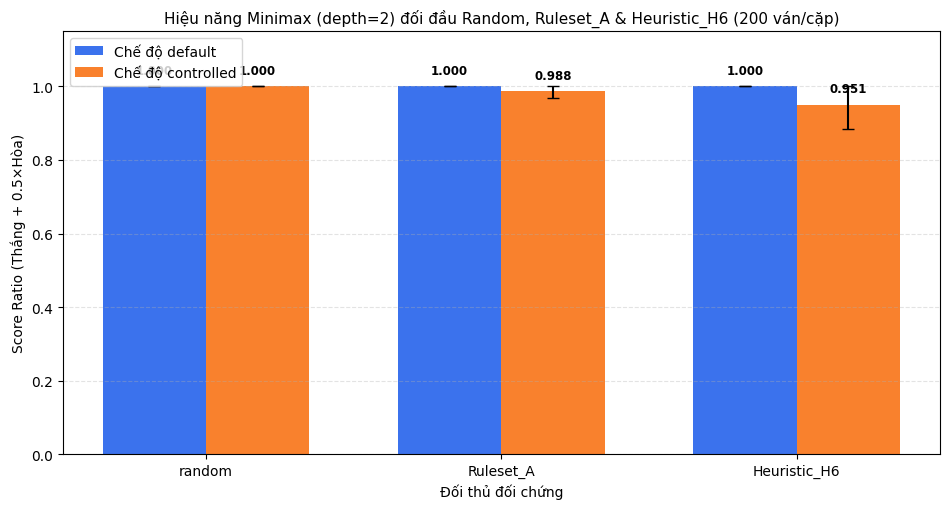

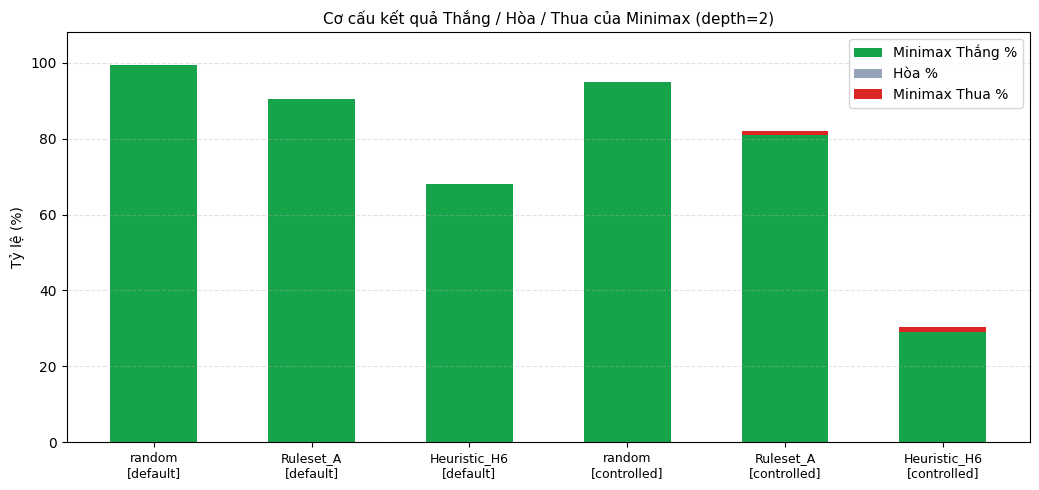

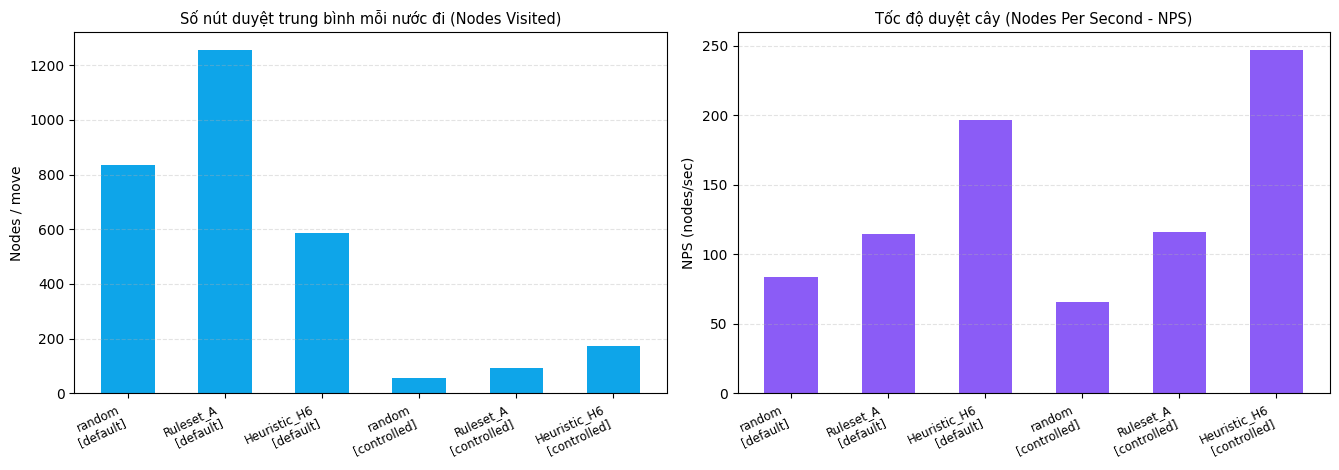

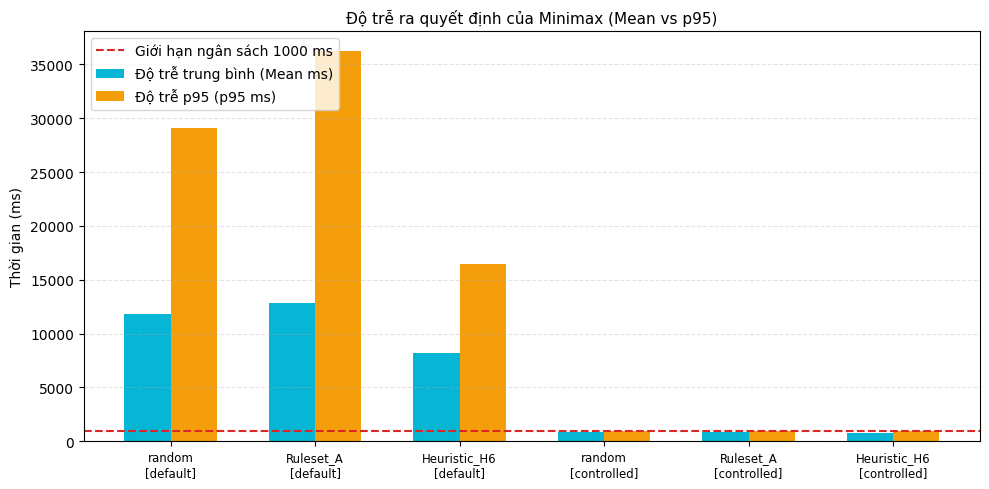

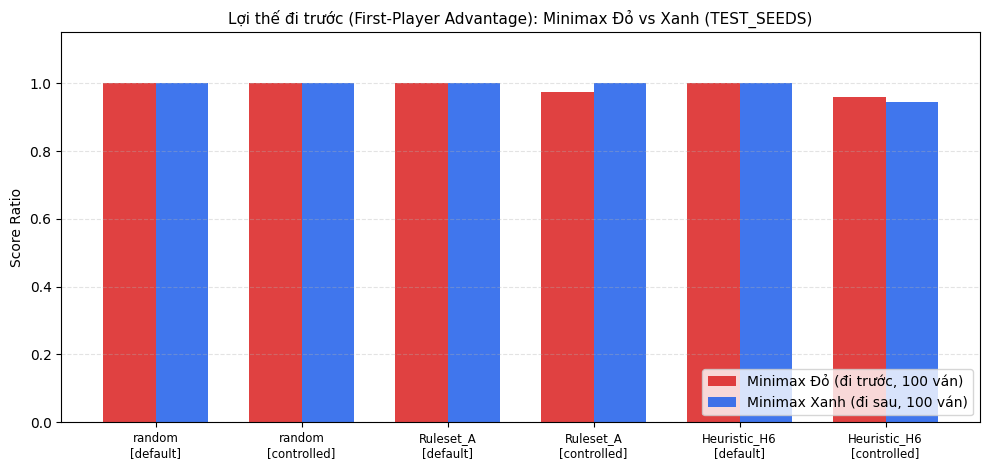

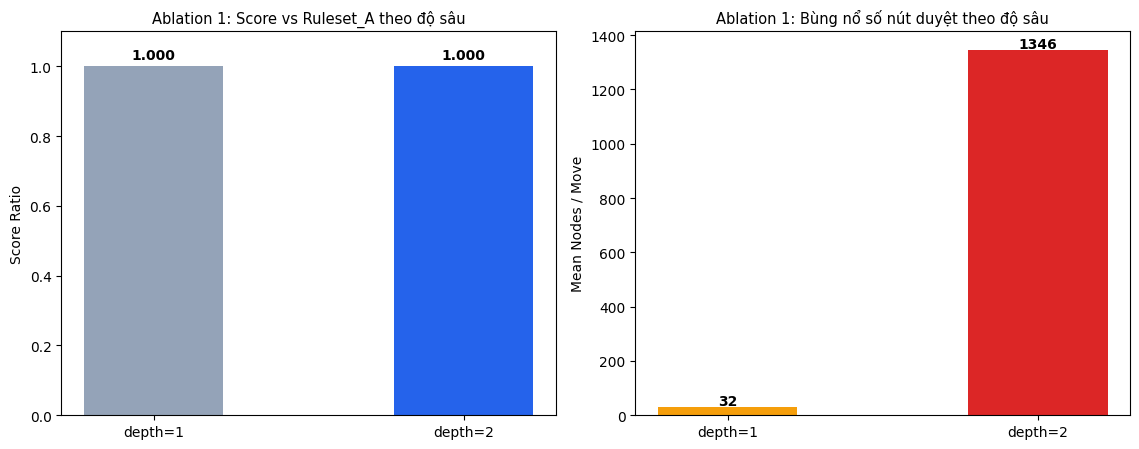

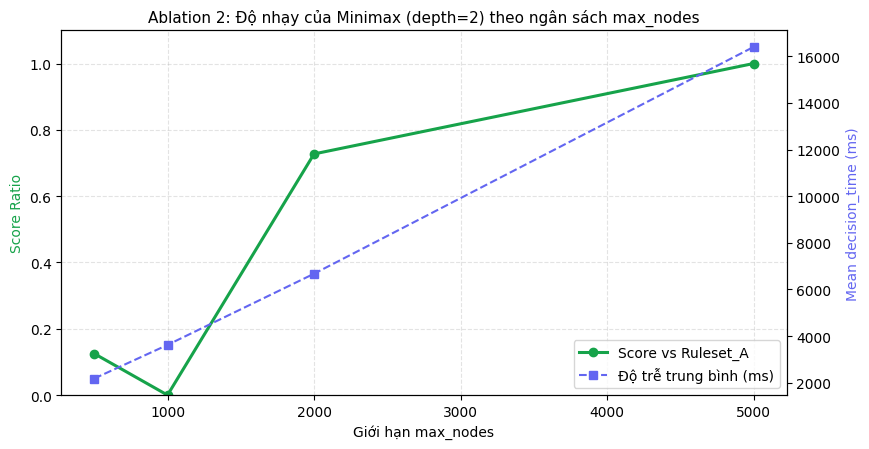

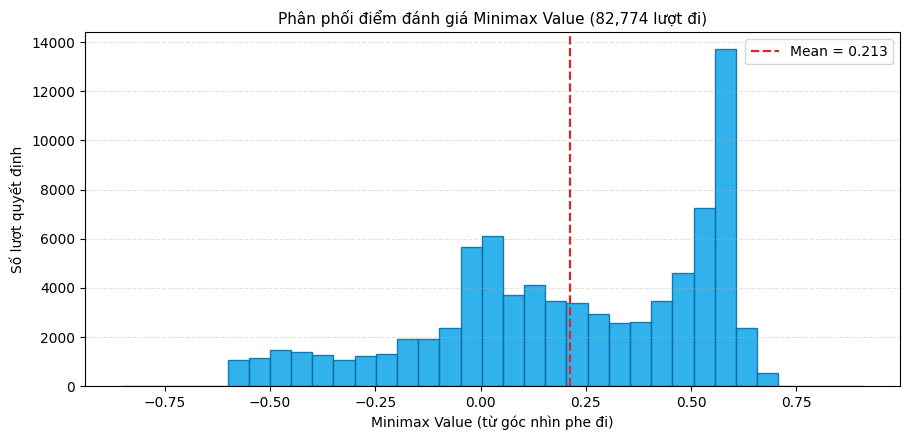

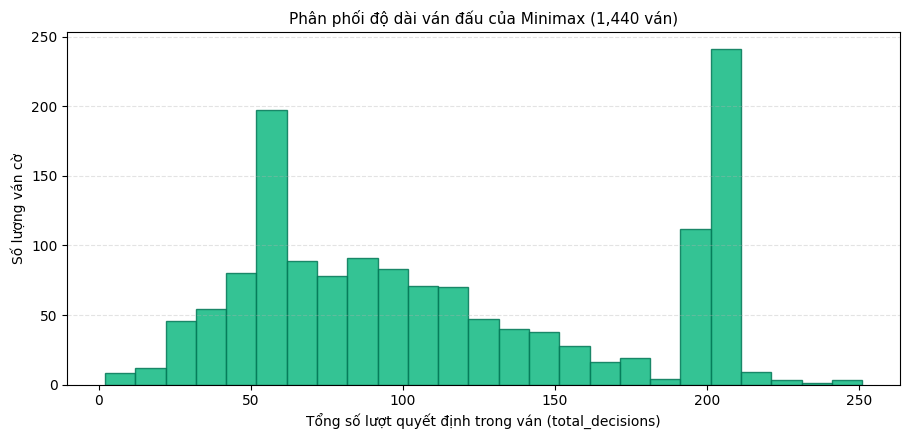

In [8]:
# ===========================================================================
# VII. Trực quan hóa kết quả theo yêu cầu của Đề tài (fig_01 -> fig_09)
# ===========================================================================
figures_dir = final_logger.run_dir / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# 1. So sánh Score Ratio & 95% CI của Minimax vs 3 đối thủ ở 2 chế độ ngân sách
fig1, ax1 = plt.subplots(figsize=(9.6, 5.2))
x_idx = np.arange(len(OPPONENTS))
w_bar = 0.35

for m_i, bmode in enumerate(benchmark_modes):
    sub_b = main_bench_df[main_bench_df["budget_mode"] == bmode]
    scores = sub_b["score"].fillna(0.0).astype(float).to_numpy()
    lows = np.clip(scores - sub_b["score_ci_low"].fillna(0.0).astype(float).to_numpy(), 0.0, None)
    highs = np.clip(sub_b["score_ci_high"].fillna(0.0).astype(float).to_numpy() - scores, 0.0, None)
    offset = (m_i - (len(benchmark_modes) - 1) / 2.0) * w_bar
    color = "#2563eb" if bmode == "default" else "#f97316"
    bars = ax1.bar(x_idx + offset, scores, width=w_bar, yerr=np.vstack([lows, highs]), capsize=4, color=color, label=f"Chế độ {bmode}", alpha=0.9)
    for b_r, sc in zip(bars, scores):
        ax1.text(b_r.get_x() + b_r.get_width() / 2.0, sc + 0.025, f"{sc:.3f}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

ax1.set_xticks(x_idx)
ax1.set_xticklabels([opp[1] for opp in OPPONENTS], fontsize=10)
ax1.set_ylim(0.0, 1.15)
ax1.set_title(f"Hiệu năng Minimax (depth=2) đối đầu Random, {RULES_LABEL} & {HEURISTIC_LABEL} ({GAMES_PER_PAIR} ván/cặp)", fontsize=11)
ax1.set_xlabel("Đối thủ đối chứng", fontsize=10)
ax1.set_ylabel("Score Ratio (Thắng + 0.5×Hòa)", fontsize=10)
ax1.legend(loc="upper left")
ax1.grid(axis="y", linestyle="--", alpha=0.35)
fig1.tight_layout()
fig1.savefig(figures_dir / "fig_01_minimax_vs_baselines_score_ci.png", dpi=200, bbox_inches="tight")
plt.show()

# 2. Tỷ lệ Thắng / Hòa / Thua (W/D/L Stacked Bar Chart)
fig2, ax2 = plt.subplots(figsize=(10.5, 5.0))
x2 = np.arange(len(main_bench_df))
lbls2 = [f"{r['opponent']}\n[{r['budget_mode']}]" for _, r in main_bench_df.iterrows()]
w_pct = main_bench_df["wins"].astype(float) / main_bench_df["total_games"].astype(float) * 100.0
d_pct = main_bench_df["draws"].astype(float) / main_bench_df["total_games"].astype(float) * 100.0
l_pct = main_bench_df["losses"].astype(float) / main_bench_df["total_games"].astype(float) * 100.0

ax2.bar(x2, w_pct, color="#16a34a", label="Minimax Thắng %", width=0.55)
ax2.bar(x2, d_pct, bottom=w_pct, color="#94a3b8", label="Hòa %", width=0.55)
ax2.bar(x2, l_pct, bottom=w_pct + d_pct, color="#dc2626", label="Minimax Thua %", width=0.55)
ax2.set_xticks(x2)
ax2.set_xticklabels(lbls2, fontsize=9)
ax2.set_ylim(0.0, 108.0)
ax2.set_title("Cơ cấu kết quả Thắng / Hòa / Thua của Minimax (depth=2)", fontsize=11)
ax2.set_ylabel("Tỷ lệ (%)", fontsize=10)
ax2.legend(loc="upper right")
ax2.grid(axis="y", linestyle="--", alpha=0.35)
fig2.tight_layout()
fig2.savefig(figures_dir / "fig_02_wdl_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

# 3. Số nút duyệt trung bình & Tốc độ duyệt cây (NPS) theo từng đối thủ
fig3, (ax3a, ax3b) = plt.subplots(1, 2, figsize=(13.5, 4.8))
ax3a.bar(x2, main_bench_df["mean_nodes_visited"].fillna(0.0).astype(float), color="#0ea5e9", width=0.55)
ax3a.set_xticks(x2)
ax3a.set_xticklabels(lbls2, rotation=25, ha="right", fontsize=8.5)
ax3a.set_title("Số nút duyệt trung bình mỗi nước đi (Nodes Visited)", fontsize=10.5)
ax3a.set_ylabel("Nodes / move")
ax3a.grid(axis="y", linestyle="--", alpha=0.35)

ax3b.bar(x2, main_bench_df["nodes_per_second"].fillna(0.0).astype(float), color="#8b5cf6", width=0.55)
ax3b.set_xticks(x2)
ax3b.set_xticklabels(lbls2, rotation=25, ha="right", fontsize=8.5)
ax3b.set_title("Tốc độ duyệt cây (Nodes Per Second - NPS)", fontsize=10.5)
ax3b.set_ylabel("NPS (nodes/sec)")
ax3b.grid(axis="y", linestyle="--", alpha=0.35)
fig3.tight_layout()
fig3.savefig(figures_dir / "fig_03_nodes_visited_and_nps.png", dpi=200, bbox_inches="tight")
plt.show()

# 4. Độ trễ ra quyết định (Mean & p95 ms) và Ngân sách 1000 ms
fig4, ax4 = plt.subplots(figsize=(10.0, 5.0))
ax4.bar(x2 - 0.16, main_bench_df["mean_decision_ms"].fillna(0.0).astype(float), width=0.32, color="#06b6d4", label="Độ trễ trung bình (Mean ms)")
ax4.bar(x2 + 0.16, main_bench_df["p95_decision_ms"].fillna(0.0).astype(float), width=0.32, color="#f59e0b", label="Độ trễ p95 (p95 ms)")
ax4.axhline(1000.0, color="#dc2626", linestyle="--", linewidth=1.5, label="Giới hạn ngân sách 1000 ms")
ax4.set_xticks(x2)
ax4.set_xticklabels(lbls2, fontsize=8.5)
ax4.set_title("Độ trễ ra quyết định của Minimax (Mean vs p95)", fontsize=11)
ax4.set_ylabel("Thời gian (ms)")
ax4.legend(loc="upper left")
ax4.grid(axis="y", linestyle="--", alpha=0.35)
fig4.tight_layout()
fig4.savefig(figures_dir / "fig_04_latency_and_budget_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

# 5. Lợi thế đi trước: So sánh 100 ván Đỏ (đi trước) vs 100 ván Xanh (đi sau)
fig5, ax5 = plt.subplots(figsize=(10.0, 4.8))
red_scores, blue_scores, pair_names = [], [], []
for opp in OPPONENTS:
    opp_l = opp[1]
    for bmode in benchmark_modes:
        sub_rb = red_blue_df[(red_blue_df["opponent"] == opp_l) & (red_blue_df["budget_mode"] == bmode) & (red_blue_df["agent"].str.contains("Minimax"))]
        sc_r = float(sub_rb[sub_rb["side"] == "red"]["score_ratio"].iloc[0]) if not sub_rb[sub_rb["side"] == "red"].empty else 0.0
        sc_b = float(sub_rb[sub_rb["side"] == "blue"]["score_ratio"].iloc[0]) if not sub_rb[sub_rb["side"] == "blue"].empty else 0.0
        red_scores.append(sc_r)
        blue_scores.append(sc_b)
        pair_names.append(f"{opp_l}\n[{bmode}]")

xr5 = np.arange(len(pair_names))
ax5.bar(xr5 - 0.18, red_scores, width=0.36, color="#dc2626", alpha=0.88, label="Minimax Đỏ (đi trước, 100 ván)")
ax5.bar(xr5 + 0.18, blue_scores, width=0.36, color="#2563eb", alpha=0.88, label="Minimax Xanh (đi sau, 100 ván)")
ax5.set_xticks(xr5)
ax5.set_xticklabels(pair_names, fontsize=8.5)
ax5.set_ylim(0.0, 1.15)
ax5.set_title("Lợi thế đi trước (First-Player Advantage): Minimax Đỏ vs Xanh (TEST_SEEDS)", fontsize=11)
ax5.set_ylabel("Score Ratio")
ax5.legend(loc="lower right")
ax5.grid(axis="y", linestyle="--", alpha=0.35)
fig5.tight_layout()
fig5.savefig(figures_dir / "fig_05_red_vs_blue_advantage.png", dpi=200, bbox_inches="tight")
plt.show()

# 6. Ablation 1: Khảo sát độ sâu (depth=1 vs depth=2)
df_abl_d = ablation_df[ablation_df["ablation_type"] == "search_depth"]
fig6, (ax6a, ax6b) = plt.subplots(1, 2, figsize=(11.5, 4.6))
x6 = np.arange(len(df_abl_d))
ax6a.bar(x6, df_abl_d["score"].astype(float), color=["#94a3b8", "#2563eb"], width=0.45)
ax6a.set_xticks(x6)
ax6a.set_xticklabels([f"depth={v}" for v in df_abl_d["value"]], fontsize=10)
ax6a.set_ylim(0.0, 1.1)
ax6a.set_title(f"Ablation 1: Score vs {RULES_LABEL} theo độ sâu", fontsize=10.5)
ax6a.set_ylabel("Score Ratio")
for xi, sc in zip(x6, df_abl_d["score"].astype(float)):
    ax6a.text(xi, sc + 0.02, f"{sc:.3f}", ha="center", fontweight="bold")

ax6b.bar(x6, df_abl_d["mean_nodes_visited"].astype(float), color=["#f59e0b", "#dc2626"], width=0.45)
ax6b.set_xticks(x6)
ax6b.set_xticklabels([f"depth={v}" for v in df_abl_d["value"]], fontsize=10)
ax6b.set_title("Ablation 1: Bùng nổ số nút duyệt theo độ sâu", fontsize=10.5)
ax6b.set_ylabel("Mean Nodes / Move")
for xi, nd in zip(x6, df_abl_d["mean_nodes_visited"].astype(float)):
    ax6b.text(xi, nd + 5, f"{nd:.0f}", ha="center", fontweight="bold")
fig6.tight_layout()
fig6.savefig(figures_dir / "fig_06_ablation_depth_1_vs_2.png", dpi=200, bbox_inches="tight")
plt.show()

# 7. Ablation 2: Đường cong độ nhạy ngân sách tìm kiếm (max_nodes = 500 -> 5000)
df_abl_b = ablation_df[ablation_df["ablation_type"] == "search_budget"].sort_values("value")
fig7, ax7 = plt.subplots(figsize=(8.8, 4.6))
ax7.plot(df_abl_b["value"].astype(int), df_abl_b["score"].astype(float), marker="o", linewidth=2.2, color="#16a34a", label=f"Score vs {RULES_LABEL}")
ax7.set_title(f"Ablation 2: Độ nhạy của Minimax (depth=2) theo ngân sách max_nodes", fontsize=11)
ax7.set_xlabel("Giới hạn max_nodes", fontsize=10)
ax7.set_ylabel("Score Ratio", color="#16a34a", fontsize=10)
ax7.set_ylim(0.0, 1.1)
ax7.grid(True, linestyle="--", alpha=0.35)

ax7_lat = ax7.twinx()
ax7_lat.plot(df_abl_b["value"].astype(int), df_abl_b["mean_decision_ms"].astype(float), marker="s", linestyle="--", color="#6366f1", label="Độ trễ trung bình (ms)")
ax7_lat.set_ylabel("Mean decision_time (ms)", color="#6366f1", fontsize=10)

h_a1, l_a1 = ax7.get_legend_handles_labels()
h_a2, l_a2 = ax7_lat.get_legend_handles_labels()
ax7.legend(h_a1 + h_a2, l_a1 + l_a2, loc="lower right")
fig7.tight_layout()
fig7.savefig(figures_dir / "fig_07_ablation_search_budget_curve.png", dpi=200, bbox_inches="tight")
plt.show()

# 8. Phân phối điểm lượng giá Minimax Value thu thập từ moves.csv
mm_scores_list = []
for chunk in pd.read_csv(moves_path, usecols=["agent_name", "heuristic_score"], chunksize=50_000, low_memory=False):
    sub = chunk[chunk["agent_name"].str.contains("Minimax|MM", case=False, na=False) & chunk["heuristic_score"].notna()]
    if not sub.empty:
        vals = sub["heuristic_score"].astype(float).to_numpy()
        vals = vals[np.abs(vals) < TERMINAL_WIN_SCORE * 0.5]
        if vals.size > 0:
            mm_scores_list.append(vals)

all_mm_scores = np.concatenate(mm_scores_list) if mm_scores_list else np.array([], dtype=float)
if all_mm_scores.size > 0:
    fig8, ax8 = plt.subplots(figsize=(9.2, 4.5))
    ax8.hist(all_mm_scores, bins=35, color="#0ea5e9", edgecolor="#0369a1", alpha=0.85)
    mean_val = float(np.mean(all_mm_scores))
    ax8.axvline(mean_val, color="#dc2626", linestyle="--", linewidth=1.6, label=f"Mean = {mean_val:.3f}")
    ax8.set_title(f"Phân phối điểm đánh giá Minimax Value ({all_mm_scores.size:,} lượt đi)", fontsize=11)
    ax8.set_xlabel("Minimax Value (từ góc nhìn phe đi)")
    ax8.set_ylabel("Số lượt quyết định")
    ax8.legend()
    ax8.grid(axis="y", linestyle="--", alpha=0.35)
    fig8.tight_layout()
    fig8.savefig(figures_dir / "fig_08_minimax_eval_distribution.png", dpi=200, bbox_inches="tight")
    plt.show()

# 9. Phân phối độ dài ván cờ (Game Length)
games_df_final = pd.read_csv(games_path)
fig9, ax9 = plt.subplots(figsize=(9.2, 4.5))
ax9.hist(games_df_final["total_decisions"].astype(float), bins=25, color="#10b981", edgecolor="#047857", alpha=0.85)
ax9.set_title(f"Phân phối độ dài ván đấu của Minimax ({len(games_df_final):,} ván)", fontsize=11)
ax9.set_xlabel("Tổng số lượt quyết định trong ván (total_decisions)")
ax9.set_ylabel("Số lượng ván cờ")
ax9.grid(axis="y", linestyle="--", alpha=0.35)
fig9.tight_layout()
fig9.savefig(figures_dir / "fig_09_game_length_distribution.png", dpi=200, bbox_inches="tight")
plt.show()


In [9]:
# 10. Xuất file JSON cây tìm kiếm Minimax và vẽ biểu đồ cây phân cấp (fig_10_minimax_search_tree.png)
import matplotlib.pyplot as plt
from pathlib import Path
from agents import MinimaxAgent
from agents.tree_exporter import export_minimax_tree_json, plot_minimax_tree_from_json
from commander_game_engine.initial_setup import create_initial_state

try:
    target_dir = final_logger.run_dir
except NameError:
    target_dir = Path("research/results/10_test_minimax_agent/mmx_20261114T013919Z")

target_fig_dir = target_dir / "figures"
target_fig_dir.mkdir(parents=True, exist_ok=True)

sample_json_path = target_dir / "minimax_tree_sample.json"
fig10_path = target_fig_dir / "fig_10_minimax_search_tree.png"

demo_minimax = MinimaxAgent(name="Minimax_Tree_Demo", config={"depth": 2})
demo_state = create_initial_state()

export_minimax_tree_json(
    agent=demo_minimax,
    state=demo_state,
    filepath=sample_json_path,
    top_k_ply1=3,
    top_k_ply2=2,
)
print("Đã xuất file JSON cây tìm kiếm Minimax vào:", sample_json_path)

plot_minimax_tree_from_json(
    json_path_or_dict=sample_json_path,
    output_png_path=fig10_path,
    figsize=(13, 7.5),
    dpi=300,
)
print("Đã vẽ và lưu biểu đồ cây tìm kiếm Minimax vào:", fig10_path)
plt.show()

print("Đã hoàn tất trực quan hóa và lưu đầy đủ 10 biểu đồ PNG vào:", target_fig_dir)


Đã xuất file JSON cây tìm kiếm Minimax vào: D:\Commander-Chess-AI\research\results\10_test_minimax_agent\mmx_20261114T013919Z\minimax_tree_sample.json
Đã vẽ và lưu biểu đồ cây tìm kiếm Minimax vào: D:\Commander-Chess-AI\research\results\10_test_minimax_agent\mmx_20261114T013919Z\figures\fig_10_minimax_search_tree.png
Đã hoàn tất trực quan hóa và lưu đầy đủ 10 biểu đồ PNG vào: D:\Commander-Chess-AI\research\results\10_test_minimax_agent\mmx_20261114T013919Z\figures


## VIII. Nhận xét và kết luận

*(Chỉ điền nhận xét định lượng sau khi chạy xong thực nghiệm và đối chiếu với W&B dashboard + CSV đầu ra)*

1. **Hiệu năng Minimax (`depth = 2`) so với các Baseline:**
   - So sánh tỷ lệ thắng/hòa/thua và Score Ratio trước `RandomAgent`, `RuleBasedAgent` (`Ruleset_A`), và `HeuristicAgent` (`H6_tuned`).
   - Minimax giải quyết triệt để điểm mù nào của Heuristic 1-ply (ví dụ: phát hiện bẫy phản công 2 nước, phối hợp chiếu bắt đôi)?
2. **Chi phí tính toán và số nút duyệt:**
   - Số nút duyệt trung bình mỗi nước (`mean_nodes_visited`) và độ trễ (`mean_decision_ms`) thay đổi ra sao giữa các đối thủ?
   - Tốc độ duyệt cây (NPS) của Minimax đạt bao nhiêu trên CPU?
3. **Ảnh hưởng của chế độ ngân sách (`default` vs `controlled 1000 ms`):**
   - Giới hạn thời gian 1000 ms có làm giảm sức cờ của Minimax không? Tỷ lệ nước vượt ngân sách (`budget_exceeded`) là bao nhiêu?
4. **Kết quả Ablation Analysis:**
   - **Ablation 1 (Độ sâu `depth=1` vs `depth=2`):** Bước nhảy sức cờ và chi phí số nút khi tăng từ 1 lên 2 tầng tìm kiếm.
   - **Ablation 2 (Ngân sách `max_nodes`):** Mức độ suy giảm sức mạnh khi bóp nghẹt ngân sách tìm kiếm từ 5000 xuống 500 nodes.
5. **Động lực cho Alpha-Beta Pruning (Bài 11):**
   - Tại sao Minimax thuần bị chặn đứng ở `depth = 2` do bùng nổ tổ hợp ($O(b^2)$), và việc cắt tỉa các nhánh bất khả thi ở bài 11 sẽ mở đường cho `depth = 3` như thế nào?